# Задача 3. Распространение и детектирование света

Найти первое достижение границы фотоном из точки $\mathbf p$ в направлении
$\mathbf n$, определить попадание на ФЭУ, разыграть число фотоэлектронов
и смоделировать событие 1 МэВ в центре. Рассеянием и поглощением в объёме
пренебречь. На границе фотон поглощается полностью, отражений нет.

Методы находятся в [detector.py](detector.py), функция моделирования
события — в [light_simulation.py](light_simulation.py).

Для единичного направления луч имеет вид $\mathbf x(t)=\mathbf p+t\mathbf n$.
Из уравнения $|\mathbf p+t\mathbf n|^2=R^2$ для внутреннего источника:
$$t=-\mathbf p\cdot\mathbf n+
\sqrt{(\mathbf p\cdot\mathbf n)^2+R^2-|\mathbf p|^2}.$$
Точка $\mathbf q=\mathbf p+t\mathbf n$ проверяется методом `find_pmt`.

**Соглашение об отклике.** В 3 задаче число фотоэлектронов
задано как $k\sim\operatorname{Poisson}(a)$. Именно это условие и реализуется:
$a=0{,}5$ — среднее на один попавший фотон. В общей концепции тот же символ
назван вероятностью хотя бы одного фотоэлектрона. Для распределения Пуассона
эти величины связаны как $P(k\ge1)=1-e^{-a}$ и не совпадают.
Если задана вероятность $P(k\ge1)=0{,}5$, среднее Пуассона должно быть
$-\ln(1-0{,}5)=\ln2$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from detector import Detector
from source import Source
from light_simulation import simulate_event
%matplotlib inline

detector = Detector(seed=43)
source = Source(seed=42)
event = simulate_event(detector, source, E=1.0, position=(0, 0, 0))
print('Испущено фотонов:', event['photon_count'])
print('Попаданий на фотокатоды:', int(event['hits'].sum()))
print('Фотоэлектроны по каналам:', event['photoelectrons'].tolist())
print('Полный заряд Q:', event['Q'], 'фотоэлектронов')

Испущено фотонов: 10000
Попаданий на фотокатоды: 253
Фотоэлектроны по каналам: [2, 5, 1, 5, 1, 0, 4, 7, 1, 4, 2, 1, 1, 3, 2, 4, 8, 1, 4, 3, 1, 2, 0, 2, 5, 2, 2, 2, 3, 4, 6, 1, 3, 6, 2, 3, 2, 5, 5, 2]
Полный заряд Q: 117 фотоэлектронов


Отклик принадлежит классу `Detector`: параметр $a$ характеризует фотокатод,
а источник определяет испускание фотонов. Метод `sample_photoelectrons`
вызывает генератор Пуассона только после попадания фотона на фотокатод.
Каждый ФЭУ имеет отдельный канал; полный заряд — сумма по 40 каналам.

In [2]:
response = Detector(seed=44).sample_photoelectrons(size=100000)
print('Среднее отклика на один попавший фотон:', response.mean())
print('Дисперсия отклика:', response.var())
print('Вероятность ненулевого отклика при среднем a=0.5:',
      1-np.exp(-detector.a))
print('Среднее Пуассона для вероятности ненулевого отклика 0.5:',
      -np.log(1-0.5))

Среднее отклика на один попавший фотон: 0.49949
Дисперсия отклика: 0.49771973990000007
Вероятность ненулевого отклика при среднем a=0.5: 0.3934693402873666
Среднее Пуассона для вероятности ненулевого отклика 0.5: 0.6931471805599453


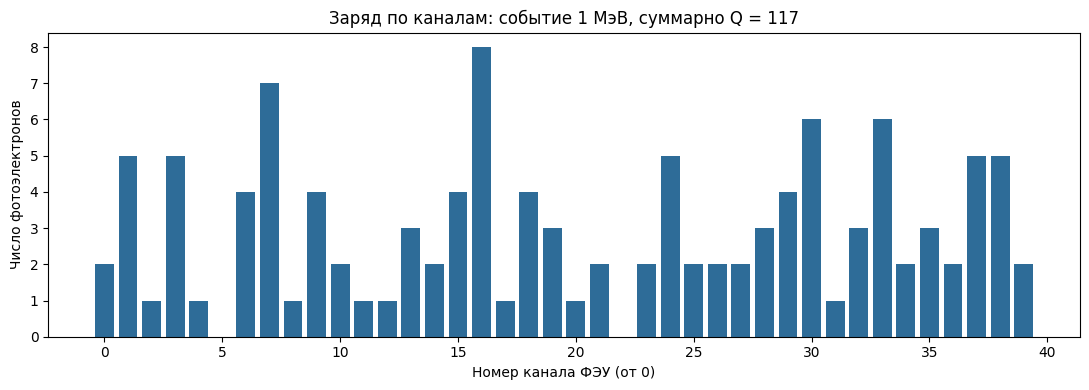

In [3]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(np.arange(detector.N), event['photoelectrons'], color='#2E6C98')
ax.set(xlabel='Номер канала ФЭУ (от 0)', ylabel='Число фотоэлектронов',
       title=f"Заряд по каналам: событие 1 МэВ, суммарно Q = {event['Q']}")
fig.tight_layout()
Path('figures').mkdir(exist_ok=True)
fig.savefig('figures/single_event_charge.png', dpi=150, bbox_inches='tight')
plt.show()

Для центрального изотропного источника и неперекрывающихся чувствительных
областей $p=Nr^2/(4R^2)=0{,}025$. При $M=YE$ испущенных фотонах:
$$\langle Q\rangle=Mpa,\qquad
\operatorname{Var}(Q)=M[pa+p(1-p)a^2].$$
Площадь одного фотокатода в выбранной модели равна $\pi r^2$, а площадь
сферы — $4\pi R^2$. Поэтому в приведённой в условии формуле без $1/4$
ожидаемый заряд завышен в четыре раза.

In [4]:
p = detector.N*detector.r**2/(4*detector.R**2)
M = event['photon_count']
mean = M*p*detector.a
std = np.sqrt(M*(p*detector.a+p*(1-p)*detector.a**2))
given_formula = detector.a*source.Y*detector.N*detector.r**2/detector.R**2
print(f'Правильное ожидание: {mean:.3f}')
print(f'Стандартное отклонение: {std:.3f}')
print(f"Полученный Q: {event['Q']}, отклонение {(event['Q']-mean)/std:.3f} sigma")
print(f'Формула без 1/4: {given_formula:.3f}')

Правильное ожидание: 125.000
Стандартное отклонение: 13.636
Полученный Q: 117, отклонение -0.587 sigma
Формула без 1/4: 500.000


Полученный заряд согласуется с ожиданием 125 фотоэлектронов в пределах
статистических флуктуаций. Все случайные величины воспроизводимы благодаря
явно заданным seed источника и детектора.